In [1]:
import pandas as pd
df=pd.read_excel('cleaned_dataset.xlsx')

Step 1: Perform complete exploratory data analysis.

In [3]:
df.shape

(8790, 10)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8790 non-null   str           
 1   type          8790 non-null   str           
 2   title         8790 non-null   str           
 3   director      8790 non-null   str           
 4   country       8790 non-null   str           
 5   date_added    8790 non-null   datetime64[us]
 6   release_year  8790 non-null   int64         
 7   rating        8790 non-null   str           
 8   duration      8790 non-null   str           
 9   listed_in     8790 non-null   str           
dtypes: datetime64[us](1), int64(1), str(8)
memory usage: 1.5 MB


In [8]:
df['type'].value_counts()

type
Movie      6126
TV Show    2664
Name: count, dtype: int64

In [6]:
df.describe()

,date_added,release_year
count,8790,8790.000000
mean,2019-05-17 21:44:01.638225,2014.183163
min,2008-01-01 00:00:00,1925.000000
25%,2018-04-06 00:00:00,2013.000000
50%,2019-07-03 00:00:00,2017.000000
75%,2020-08-19 18:00:00,2019.000000
max,2021-09-25 00:00:00,2021.000000
std,NaN,8.825466


Step 2: Identify key content trends and patterns.



Based on the exploratory analysis, the following key patterns have been identified:

*   **Geographic Patterns:** The United States is the dominant content producer, followed by India and the United Kingdom. Emerging markets such as Pakistan, South Korea, and Japan are also present in the top 10, indicating a growing focus on Asian markets.
*   **Temporal Patterns:** Content production remained low until 2015, after which it experienced a sharp and rapid increase. The highest peak was observed in 2018. A decline in production volume occurred after 2019, which may be linked to the COVID-19 pandemic and incomplete data for 2021.
*   **Audience and Rating Patterns:** Adult content (TV-MA, R, PG-13) represents the largest share of the library. While Movies are heavily skewed towards adult and teen audiences, TV Shows show a more balanced distribution across Kids, Teens, and Adults.

Step 3: Develop multiple visual dashboards.

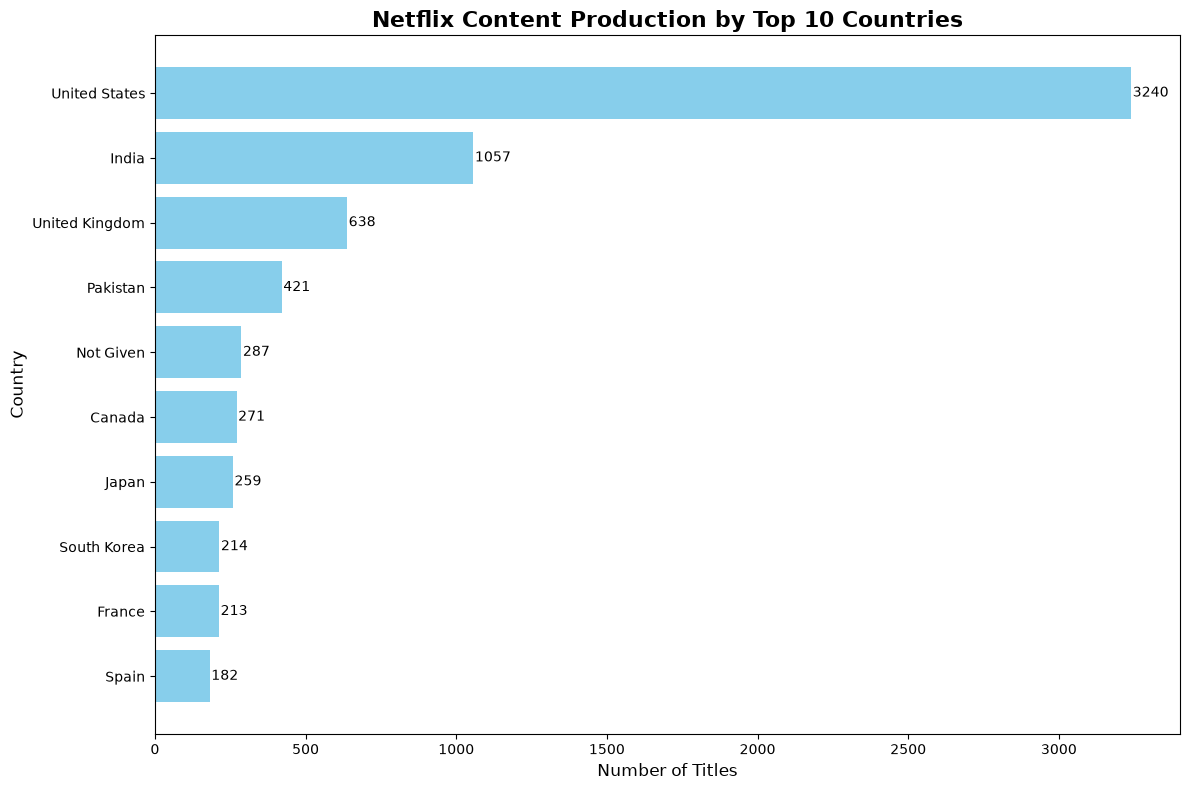

In [11]:
import matplotlib.pyplot as plt

df_country = df.dropna(subset=['country']).copy()
df_country['country'] = df_country['country'].str.split(', ')
df_country = df_country.explode('country')
df_country['country'] = df_country['country'].str.strip()
top10 = df_country['country'].value_counts().head(10)

plt.figure(figsize=(12, 8))
plt.barh(top10.index, top10.values, color='skyblue')
plt.title('Netflix Content Production by Top 10 Countries', fontsize=16, fontweight='bold')
plt.xlabel('Number of Titles', fontsize=12)
plt.ylabel('Country', fontsize=12)

for index, value in enumerate(top10.values):
    plt.text(value + 5, index, str(value), va='center', fontsize=10)

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

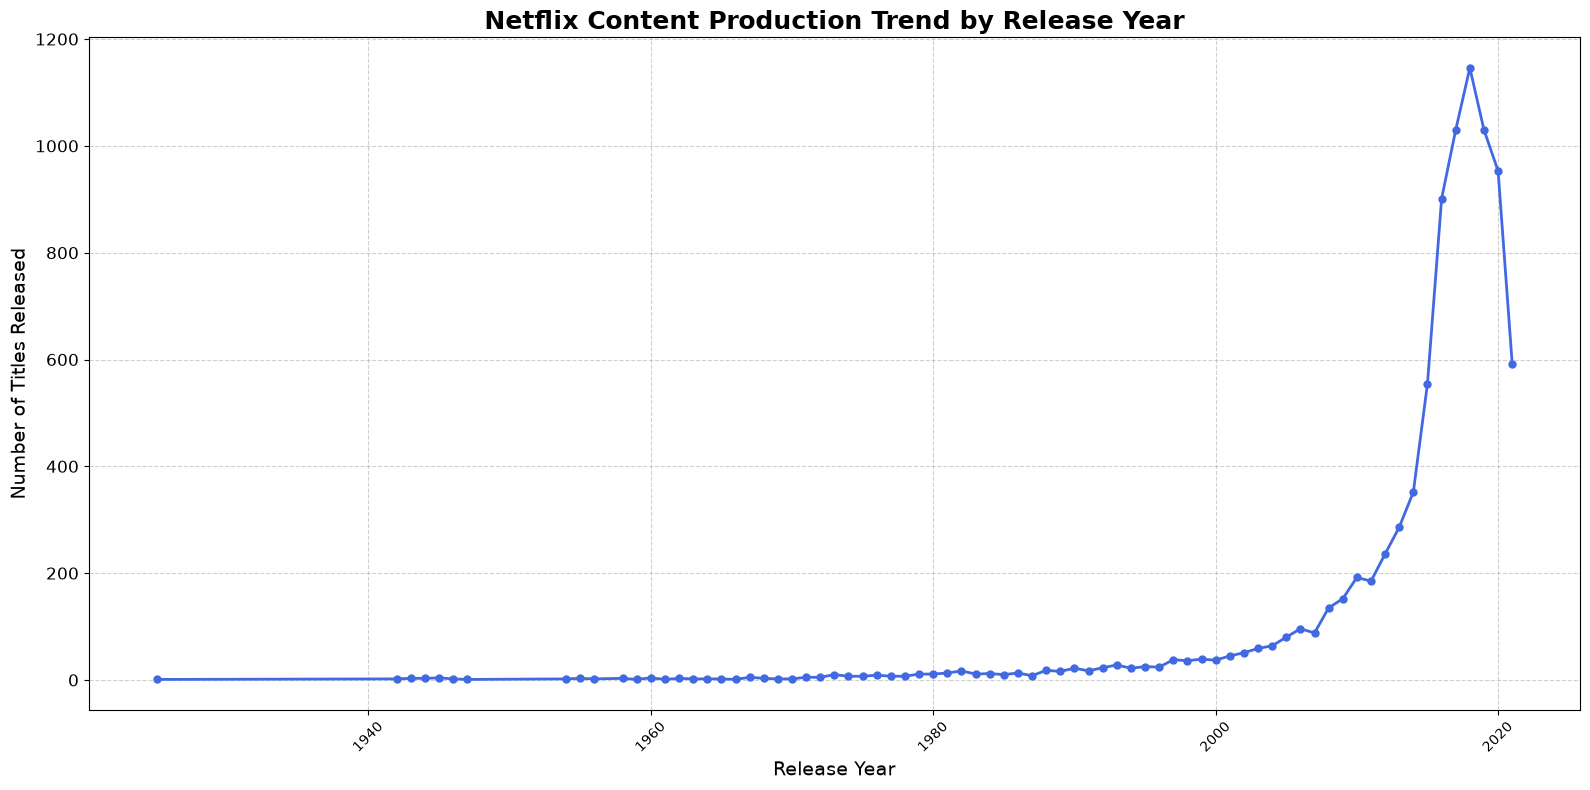

In [14]:
import matplotlib.pyplot as plt

yearly_counts = df['release_year'].value_counts().sort_index()

plt.figure(figsize=(16, 8))
plt.plot(yearly_counts.index, yearly_counts.values, marker='o', linestyle='-', color='royalblue', linewidth=2, markersize=5)
plt.title('Netflix Content Production Trend by Release Year', fontsize=18, fontweight='bold')
plt.xlabel('Release Year', fontsize=14)
plt.ylabel('Number of Titles Released', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(rotation=45, fontsize=10)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

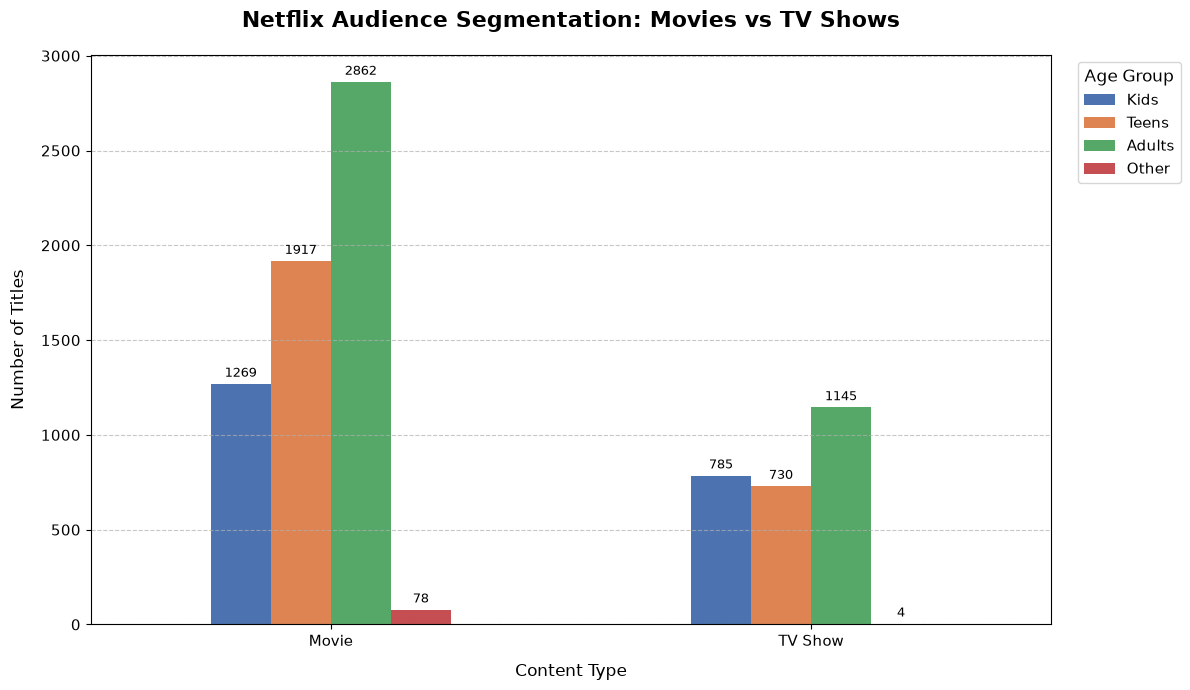

In [15]:
import matplotlib.pyplot as plt
import pandas as pd

age_mapping = {
    'G': 'Kids', 'TV-Y': 'Kids', 'TV-Y7': 'Kids', 'TV-Y7-FV': 'Kids',
    'TV-G': 'Kids', 'PG': 'Kids', 'TV-PG': 'Kids',
    'PG-13': 'Teens', 'TV-14': 'Teens',
    'R': 'Adults', 'NC-17': 'Adults', 'TV-MA': 'Adults',
    'NR': 'Other', 'UR': 'Other'
}

df['age_group'] = df['rating'].map(age_mapping)
age_crosstab = pd.crosstab(df['type'], df['age_group'])
age_crosstab = age_crosstab[['Kids', 'Teens', 'Adults', 'Other']]

ax = age_crosstab.plot(kind='bar', figsize=(12, 7), rot=0, color=['#4C72B0', '#DD8452', '#55A868', '#C44E52'])
plt.title('Netflix Audience Segmentation: Movies vs TV Shows', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Content Type', fontsize=12, labelpad=10)
plt.ylabel('Number of Titles', fontsize=12, labelpad=10)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.legend(title='Age Group', title_fontsize='12', fontsize='11', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

Step 4: Generate actionable business insights.

Based on the data analysis, the following strategic recommendations are proposed for Netflix:

1.  **Expand Investments in High-Potential Asian Markets:** 
    *   *Data Support:* India and Pakistan are among the top 10 content producers, driven by their massive populations and growing demand.
    *   *Action:* Netflix should continue localizing content and increasing production budgets in these regions to capture a larger subscriber base.

2.  **Revitalize Post-Pandemic Content Production:** 
    *   *Data Support:* Production volume dropped significantly after 2019 (peaking in 2018).
    *   *Action:* Netflix should ramp up original content production to pre-pandemic levels to maintain subscriber engagement and reduce churn.

3.  **Implement a Segmented Format Strategy:** 
    *   *Data Support:* Movies are heavily skewed towards Adults and Teens, while TV Shows maintain a balanced distribution across Kids, Teens, and Adults.
    *   *Action:* Netflix should continue producing adult-oriented Movies to satisfy mature audiences, while investing more in family-friendly TV Shows to capture and retain younger viewers.

4.  **Reduce Geographic Over-Reliance:** 
    *   *Data Support:* The United States accounts for the highest content volume by a significant margin.
    *   *Action:* While maintaining its strong US pipeline, Netflix should diversify its geographic portfolio (e.g., investing more in Latin America, Africa, and Europe) to mitigate risks associated with market saturation in North America.

Step 5: Prepare and present the final analytical report.

# Netflix Business Intelligence Report

## Executive Summary
This report provides a comprehensive analysis of Netflix's content library. By examining geographic distribution, historical release trends, and audience age ratings, we identify key patterns in Netflix's content strategy. The findings highlight the United States' dominance in content production, a massive surge in releases after 2015, and a strategic focus on adult audiences while maintaining a balanced portfolio for younger viewers through TV Shows.

## 1. Data Overview & Methodology
The dataset consists of 8,790 rows and 12 columns, containing information about Netflix Movies and TV Shows. Data cleaning involved removing "Not Given" placeholder values in the country column. For audience analysis, ratings were grouped into four categories:
*   **Kids:** G, TV-Y, TV-Y7, TV-Y7-FV, TV-G, PG, TV-PG
*   **Teens:** PG-13, TV-14
*   **Adults:** R, NC-17, TV-MA
*   **Other:** NR, UR

## 2. Key Content Trends and Patterns
*   **Geographic Patterns:** The United States is the dominant content producer, followed by India and the United Kingdom. Emerging markets such as Pakistan, South Korea, and Japan are also present in the top 10, indicating a growing focus on Asian markets.
*   **Temporal Patterns:** Content production remained low until 2015, after which it experienced a sharp and rapid increase. The highest peak was observed in 2018. A decline in production volume occurred after 2019, which may be linked to the COVID-19 pandemic and incomplete data for 2021.
*   **Audience and Rating Patterns:** Adult content (TV-MA, R, PG-13) represents the largest share of the library. While Movies are heavily skewed towards adult and teen audiences, TV Shows show a more balanced distribution across Kids, Teens, and Adults.

## 3. Visual Dashboards
The following visualizations support the findings of this report:
*   **Figure 1:** Top 10 Content Producing Countries (Geographic Distribution).
*   **Figure 2:** Netflix Content Production Trend by Release Year (Temporal Analysis).
*   **Figure 3:** Audience Segmentation by Content Type (Rating Analysis).

## 4. Actionable Business Recommendations
Based on the data analysis, the following strategic recommendations are proposed for Netflix:
1.  **Expand Investments in High-Potential Asian Markets:** Continue localizing content in India and Pakistan to capture their massive populations and growing demand.
2.  **Revitalize Post-Pandemic Content Production:** Ramp up original content production to pre-pandemic levels to maintain subscriber engagement and reduce churn.
3.  **Implement a Segmented Format Strategy:** Continue producing adult-oriented Movies while investing more in family-friendly TV Shows to capture younger viewers.
4.  **Reduce Geographic Over-Reliance:** Diversify the geographic portfolio by investing more in emerging markets (e.g., Latin America, Africa) to mitigate risks associated with market saturation in North America.

## 5. Conclusion
Netflix has evolved from a low-volume content distributor to a global production powerhouse. Its strategy is heavily data-driven, focusing on adult audiences and expanding into high-growth international markets. By continuing to adapt its content strategy to regional demographics and post-pandemic production realities, Netflix is well-positioned to maintain its market leadership.